# Lab 03 – Ticket escalation

**Name:** Meron Hailu

I want to predict if a support ticket will be escalated (`escalated = 1`) or not (`0`).

The data is a small synthetic set of 900 tickets. Most tickets are not escalated, so a high accuracy can still mean the model misses the cases that matter. I compare a few classifiers, then I pick a probability cutoff from the cost of a mistake.

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay,
)

df = pd.read_csv("classification_escalation.csv")
print("shape:", df.shape)
display(df.head())
print(df.dtypes)
print("\nclass share:")
print(df["escalated"].value_counts())
print(df["escalated"].value_counts(normalize=True).round(3))
print("\nmissing:")
print(df.isna().sum())

shape: (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


complexity_score            int64
team_experience_years     float64
priority                      str
channel                       str
customer_tenure_months    float64
escalated                   int64
dtype: object

class share:
escalated
0    714
1    186
Name: count, dtype: int64
escalated
0    0.793
1    0.207
Name: proportion, dtype: float64

missing:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64


### What I notice

- 900 tickets, 5 features + the target.
- Numbers: `complexity_score`, `team_experience_years`, `customer_tenure_months`.
- Categories: `priority` (low / medium / high) and `channel` (email / web / phone).
- 186 tickets escalated (20.7%) and 714 did not (79.3%).
- Blanks: team experience 31, priority 18, tenure 22. Complexity, channel, and the target are complete.

### Assumptions

- A blank is just a missing value, not a hidden signal. I do not add a "was missing" flag.
- For numbers I will fill with the **median**, so one very large tenure does not drag the fill value.
- For priority I will fill with the **most common** value.
- I keep priority as a category. I do not turn low/medium/high into 1/2/3, because I am not sure the gaps are equal.

## 2. How I set up the problem

This is classification, not regression. The answer is only yes or no.

I treat **escalated = 1** as the positive class. Recall is "of the tickets that really escalated, how many did I catch?" Precision is "of the tickets I flagged, how many really escalated?"

I assume a missed escalation is the worse mistake. A false alarm only means someone reviews a ticket that would have been fine.

Split: 75% train, 25% test, `random_state=42`, **stratified**. I stratify so both sets stay near 21% escalated. The test set is only for the final check. I do not fit anything on it.

In [2]:
X = df.drop(columns="escalated")
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train counts:\n", y_train.value_counts().to_string())
print("Test counts:\n", y_test.value_counts().to_string())
print("Train rate:", round(y_train.mean(), 4), "| Test rate:", round(y_test.mean(), 4))

Train: (675, 5) Test: (225, 5)
Train counts:
 escalated
0    535
1    140
Test counts:
 escalated
0    179
1     46
Train rate: 0.2074 | Test rate: 0.2044


Train is 675 rows (140 escalated). Test is 225 rows (46 escalated). The rates match (0.207 vs 0.204), so the split looks fair. 46 positives is still a small test set, so I will not trust a metric that moves when only a few tickets change.

## 3. Preprocessing

I put the cleaning inside a pipeline so it is fit on training rows only (and again inside each CV fold). That way test values do not leak into the medians or the scaling.

- Numbers: median fill, then standardize (mean 0, std 1). Scaling matters for k-NN, because it uses distance. It also stops tenure (months) from drowning out complexity (a small score).
- Categories: most-frequent fill, then one-hot. Unknown categories at test time are ignored.

In [3]:
num_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols = ["priority", "channel"]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

Xt = preprocess.fit_transform(X_train)
print("Transformed train shape:", Xt.shape)
print(list(preprocess.get_feature_names_out()))
print("Medians used to fill:", preprocess.named_transformers_["num"]["imputer"].statistics_.round(2))
print("Most common categories:", preprocess.named_transformers_["cat"]["imputer"].statistics_)

Transformed train shape: (675, 9)
['num__complexity_score', 'num__team_experience_years', 'num__customer_tenure_months', 'cat__priority_high', 'cat__priority_low', 'cat__priority_medium', 'cat__channel_email', 'cat__channel_phone', 'cat__channel_web']
Medians used to fill: [ 5.   4.4 19. ]
Most common categories: ['low' 'email']


After one-hot, 5 columns become 9. On the training set the medians are complexity 5, experience 4.4 years, tenure 19 months. The most common priority is low and the most common channel is email, so those fill the blanks.

## 4. Models

I compare four models. Each one sits in a pipeline with the same preprocessing. Predictions use the default cutoff of 0.50. ROC-AUC uses the probability of class 1, so it does not depend on that cutoff.

1. Majority baseline — always says "not escalated".
2. Logistic regression.
3. Linear discriminant analysis (LDA).
4. k-NN with k = 15 (a fairly smooth k, since the positive class is rare).

In [4]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15),
}

fitted = {}
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob),
    })

results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Majority baseline,0.796,0.00,0.000,0.000,0.500
Logistic regression,0.822,0.75,0.196,0.310,0.811
LDA,0.822,0.75,0.196,0.310,0.809
k-NN (k=15),0.796,0.50,0.087,0.148,0.705


### Observations

- The baseline already has accuracy **0.796** and recall **0**. It never catches an escalation. Logistic regression and LDA only reach **0.822**, so the accuracy gain is small.
- At 0.50, logistic regression and LDA tie: precision **0.75**, recall **0.196**, F1 **0.310**. They miss about 4 out of 5 escalations.
- Their ROC-AUC is about **0.81**, so they do rank risky tickets above safe ones. The weak recall is mostly the cutoff, not a total lack of signal.
- k-NN (k=15) is the weakest: recall 0.087, F1 0.148, AUC 0.705.

## 5. A closer look at logistic regression

[[176   3]
 [ 37   9]]
               precision    recall  f1-score   support

Not escalated       0.83      0.98      0.90       179
    Escalated       0.75      0.20      0.31        46

     accuracy                           0.82       225
    macro avg       0.79      0.59      0.60       225
 weighted avg       0.81      0.82      0.78       225



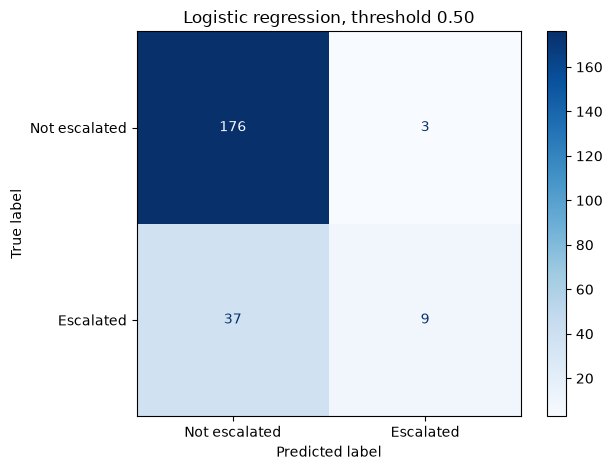

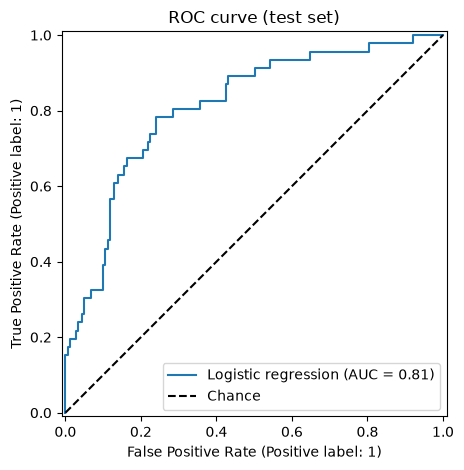

ROC-AUC: 0.811


In [5]:
lr = fitted["Logistic regression"]
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred_lr)
print(cm)
print(classification_report(y_test, y_pred_lr, target_names=["Not escalated", "Escalated"]))

ConfusionMatrixDisplay(cm, display_labels=["Not escalated", "Escalated"]).plot(cmap="Blues")
plt.title("Logistic regression, threshold 0.50")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob_lr, name="Logistic regression")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.title("ROC curve (test set)")
plt.legend()
plt.tight_layout()
plt.show()
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 3))

### Observations

The matrix is `[[176, 3], [37, 9]]`. At 0.50 the model flags 12 tickets, and 9 of them are real escalations (only 3 false alarms). It misses 37 of the 46 escalations.

The ROC curve sits above the diagonal (AUC 0.811). The model can separate the classes. It is just too shy at 0.50, because it only flags a ticket when it is quite sure.

## 6. Threshold and cost

I now flag a ticket when P(escalated) ≥ t, for t in {0.20, 0.30, 0.40, 0.50, 0.60, 0.70}.

**Cost assumption:** a missed escalation (FN) costs 5, and an unnecessary review (FP) costs 1.

`cost = 5 × FN + 1 × FP`

The 5 is an example. I do not have the real business cost. If a miss is only a bit worse than a false alarm, the best cutoff would be higher.

In [6]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
rows = []
for t in thresholds:
    y_pred_t = (y_prob_lr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    rows.append({
        "threshold": t,
        "precision": precision_score(y_test, y_pred_t, zero_division=0),
        "recall": recall_score(y_test, y_pred_t),
        "f1": f1_score(y_test, y_pred_t),
        "FP": int(fp),
        "FN": int(fn),
        "cost (5*FN + FP)": int(5 * fn + fp),
    })

threshold_table = pd.DataFrame(rows).set_index("threshold").round(3)
display(threshold_table)

best_t = threshold_table["cost (5*FN + FP)"].idxmin()
print("Cheapest threshold:", best_t)
print(threshold_table.loc[best_t])
print("Check: 5*10 + 48 =", 5 * 10 + 48)

,precision,recall,f1,FP,FN,cost (5*FN + FP)
threshold,,,,,,
0.2,0.429,0.783,0.554,48,10,98
0.3,0.549,0.609,0.577,23,18,113
0.4,0.571,0.261,0.358,9,34,179
0.5,0.750,0.196,0.310,3,37,188
0.6,1.000,0.065,0.122,0,43,215
0.7,0.000,0.000,0.000,0,46,230


Cheapest threshold: 0.2
precision            0.429
recall               0.783
f1                   0.554
FP                  48.000
FN                  10.000
cost (5*FN + FP)    98.000
Name: 0.2, dtype: float64
Check: 5*10 + 48 = 98


### Observations

- Lowering the cutoff flags more tickets. Recall goes from 0.065 at 0.60 up to 0.783 at 0.20. False alarms go from 0 up to 48, and precision falls to 0.43.
- The cheapest cutoff on this grid is **0.20** (10 misses, 48 false alarms, cost **98**). At the default 0.50 the cost is **188**.
- F1 is best at **0.30** (0.577), not at 0.20. F1 treats a miss and a false alarm as equal. My cost does not, so the two rules disagree. That is expected.
- I picked 0.20 by looking at the test set. That makes 98 a bit optimistic, because I used the same 46 positives both to choose and to score. A better plan is to choose the cutoff on validation folds, then touch the test set once.

## 7. Tuning k for k-NN

I only tune on the training set. Stratified 5-fold CV, k in {5, 9, 15, 21, 31}, scored by F1. F1 is a reasonable score while the cutoff is still 0.50, because accuracy would reward "never escalate".

The preprocessor stays inside the pipeline, so each fold refits the imputer and the scaler.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_pipe = Pipeline([("prep", preprocess), ("model", KNeighborsClassifier())])
grid = GridSearchCV(
    knn_pipe,
    param_grid={"model__n_neighbors": [5, 9, 15, 21, 31]},
    scoring="f1",
    cv=cv,
)
grid.fit(X_train, y_train)

cv_results = pd.DataFrame(grid.cv_results_)[
    ["param_model__n_neighbors", "mean_test_score", "std_test_score", "rank_test_score"]
].round(3)
display(cv_results)
print("Best:", grid.best_params_, "| CV F1:", round(grid.best_score_, 3))

best_knn = grid.best_estimator_
yp = best_knn.predict(X_test)
yprob = best_knn.predict_proba(X_test)[:, 1]
print(
    "Tuned k-NN on test -> acc %.3f  prec %.3f  rec %.3f  f1 %.3f  auc %.3f"
    % (
        accuracy_score(y_test, yp),
        precision_score(y_test, yp, zero_division=0),
        recall_score(y_test, yp),
        f1_score(y_test, yp),
        roc_auc_score(y_test, yprob),
    )
)

,param_model__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,5,0.243,0.095,1
1,9,0.198,0.065,2
2,15,0.160,0.065,3
3,21,0.146,0.056,4
4,31,0.112,0.040,5


Best: {'model__n_neighbors': 5} | CV F1: 0.243
Tuned k-NN on test -> acc 0.791  prec 0.462  rec 0.130  f1 0.203  auc 0.631


### Observations

F1 drops as k gets larger. A big neighborhood is mostly non-escalated tickets, so the vote goes to "no".

The best k is **5**, but CV F1 is only 0.243 and the fold-to-fold std is about 0.10, so the choice is shaky. On the test set this k-NN still loses to logistic regression (F1 0.203, AUC 0.631 vs AUC 0.811).

## 8. Prior, likelihood, posterior

Bayes:

`P(escalated | x) = P(x | escalated) · P(escalated) / P(x)`

- **Prior** P(escalated): how often tickets escalate before I look at the features. Here about 0.21.
- **Likelihood** P(x | escalated): how usual this kind of ticket is among tickets that did escalate.
- **Evidence** P(x): how usual this kind of ticket is overall. It rescales the answer so the probabilities add to 1.
- **Posterior** P(escalated | x): the updated chance for this ticket. Logistic regression and LDA are estimating this, and I compare it with a threshold.

Example: a hard ticket handled by a new team shows up more often in the escalated group, so the posterior moves above 0.21.

## 9. When is it worth flagging?

Take a ticket with posterior p = 0.30. Assume C_FP = 1 and C_FN = 5.

- If I escalate, I am wrong only when it would not have escalated. Expected cost = (1 − 0.30) × 1 = **0.70**.
- If I do nothing, I am wrong only when it would have escalated. Expected cost = 0.30 × 5 = **1.50**.

0.70 is smaller, so I escalate, even though 0.30 is below 0.50. The ticket is still more likely to be fine, but a miss is expensive enough that I would rather review it.

Break-even: escalate when `(1 − p) · 1 < p · 5`, which is `p > 1 / (1 + 5) = 1/6 ≈ 0.167`.

My grid did not include 0.167. The nearest point, 0.20, was also the cheapest. That lines up.

## 10. Logistic regression vs LDA on the training folds

Same 5 folds, still on the training set only, at the default 0.50 cutoff.

In [8]:
for name in ["Logistic regression", "LDA"]:
    scores = cross_validate(
        Pipeline([("prep", preprocess), ("model", models[name])]),
        X_train,
        y_train,
        cv=cv,
        scoring=["f1", "recall", "roc_auc"],
    )
    summary = {k.replace("test_", ""): round(float(v.mean()), 3) for k, v in scores.items() if k.startswith("test")}
    print(name, summary)

Logistic regression {'f1': 0.248, 'recall': 0.164, 'roc_auc': 0.744}


LDA {'f1': 0.266, 'recall': 0.179, 'roc_auc': 0.743}


On the training folds the two models are almost the same (AUC about 0.74). That CV AUC is lower than the test AUC of 0.81. With only 46 test positives, that gap is noise, not a sign that the test set is magically easier. LDA is a little higher on CV F1 (0.266 vs 0.248). I still prefer logistic regression because the scores are tied and the coefficients are easier to explain to a support lead.

## Recommendation

I would ship **logistic regression** with a cutoff near **0.17–0.20**, as a queue helper.

- It matches LDA on the test set (AUC 0.811 vs 0.809) and beats k-NN by a lot.
- At 0.50 it only catches 9 of 46 escalations. Under my 5-to-1 cost, 0.20 is cheaper (98 vs 188).
- The formula gives the same idea: flag when the probability is above about 0.17.

What I would not do:

- I would not trust accuracy. The do-nothing model scores 0.796.
- I would not deploy k-NN. Even the best k (5) only reaches test F1 0.20 and AUC 0.63.
- I would not auto-escalate and walk away. At 0.20, precision is 0.43, so most flags are false alarms. A person should still look.
- I would not use the model to punish agents or customers.

Before I trusted it on real tickets I would: pick the cutoff on validation data, check the scores by channel and priority, check that the probabilities are calibrated, and watch the error rate after launch. The 5× cost is only my assumption. If the real costs are different, the cutoff changes.

## Short answers

1. **Why is accuracy misleading?** About 79% of tickets are not escalated, so "always say no" scores 0.796 and catches nothing.
2. **Best recall, precision, and F1 at 0.50?** Logistic regression and LDA tie (recall 0.196, precision 0.75, F1 0.31). k-NN is worse. AUC: LR 0.811, LDA 0.809, k-NN 0.705. The baseline has no real ranking (AUC 0.50).
3. **What happens if I lower the threshold?** I flag more tickets. Recall goes up, misses go down, false alarms go up, precision goes down.
4. **Which threshold minimizes 5×FN + FP?** 0.20, cost 98. This is a bit optimistic because I chose it on the test set.
5. **Bayes words:** prior ≈ 0.21, likelihood is how typical the features are inside one class, evidence rescales, posterior is the model's probability.
6. **At p = 0.30, which action is cheaper?** Escalating costs 0.70, doing nothing costs 1.50. The break-even cutoff is 1/6 ≈ 0.167.
7. **What would I deploy?** Logistic regression, cutoff about 0.20, as a suggestion for staff. Not as an automatic decision.